<a href="https://colab.research.google.com/github/gflamiano/SJU-CSC-672-ML/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5

#### Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.

This cell loads the Pima Indians Diabetes dataset into a Pandas DataFrame and gets it ready to use. It does this in four steps:

1. **Import libraries.** `pandas` provides the DataFrame (a table of rows and columns), and `fetch_openml` from scikit-learn downloads datasets from OpenML.

2. **Download the data.** `fetch_openml(data_id=37, as_frame=True)` downloads the dataset as a Pandas table. We use OpenML because it hosts a copy of the original UCI file, which is no longer found on the UCI site. `.copy()` makes a separate copy so the original download stays unchanged.

3. **Name the columns.** The downloaded column names are abbreviations that are hard to read. We replace them with clear names.

4. **Convert the label to numbers.** The label is stored as text (`"tested_negative"` or `"tested_positive"`). We change it to **0** (no diabetes) and **1** (diabetes), because most analysis and machine-learning tools need numbers.

> **Note:** Run this cell only once. Running it again turns the whole `Outcome` column into 0, because it already contains numbers. If that happens, restart the kernel and run the notebook from the top.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=37, as_frame=True)
df = data.frame.copy()

df.columns = [
    "Pregnancies",               # number of times pregnant
    "Glucose",                   # plasma glucose, 2 hr oral glucose tolerance test
    "BloodPressure",             # diastolic blood pressure (mm Hg)
    "SkinThickness",             # triceps skinfold thickness (mm)
    "Insulin",                   # 2-hour serum insulin (mu U/ml)
    "BMI",                       # body mass index (kg/m^2)
    "DiabetesPedigreeFunction",  # diabetes pedigree function
    "Age",                       # age in years
    "Outcome",                   # class label
]

# OpenML stores the label as strings; convert to 0/1
df["Outcome"] = (df["Outcome"] == "tested_positive").astype(int)


#### Task 2: Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

This cell inspects the DataFrame from Task 1 to understand what it contains and to spot values that look wrong. It runs four checks in order and prints a labeled section for each.

1. **`head()`:** look at the first rows
2. **`info()`:** check the structure
3. **`describe()`:** summarize the distributions
4. **Identify placeholder values.** Some columns use 0 to mean "not recorded". These placeholder values look like real data, so Pandas does not treat them as missing. The code counts the zeros in the five columns where 0 is impossible and shows what percentage of the 768 rows they make up. `Pregnancies` is excluded because 0 is valid there. These zeros should be treated as **missing values** during data cleaning in a later task.

In [2]:
print("=" * 50)
print("head()")
print("=" * 50)
display(df.head())

print("\n" + "=" * 50)
print("info()")
print("=" * 50)
df.info()

print("\n" + "=" * 50)
print("describe()")
print("=" * 50)
display(df.describe())

print("\n" + "=" * 75)
print("PLACEHOLDER VALUES: zeros in columns where 0 is impossible")
print("=" * 75)
cols_with_placeholders = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[cols_with_placeholders] == 0).sum()
zero_percent = (zero_counts / len(df) * 100).round(1)

display(pd.DataFrame({"Zero count": zero_counts, "Percent of rows (%)": zero_percent}))

head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



PLACEHOLDER VALUES: zeros in columns where 0 is impossible


,Zero count,Percent of rows (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


#### Task 3: Quantify and handle implicit missing values using SimpleImputer.

In Task 2 we found that some columns use 0 as a placeholder for "not recorded". This cell turns those zeros into real missing values, counts them, and fills them in.

1. **Convert zeros to `NaN`.** In `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`, every 0 is replaced with `np.nan`, Pandas' marker for a missing value. `Pregnancies` is left alone because 0 is valid there.

2. **Quantify the missing values.** `isnull().sum()` counts the missing values in each column, and the code also shows what percentage of the 768 rows that is.

3. **Fill the gaps with `SimpleImputer`.** It replaces each missing value with a statistic calculated from the rest of the column. We use `strategy="median"` because columns like `Insulin` are skewed, and a few very large values would pull the mean upward. `fit_transform()` calculates the median of each column, ignoring `NaN`, and fills the gaps with it.

4. **Verify the result.** The code prints the median used for each column and confirms that no missing values remain.

In [3]:
import numpy as np
from sklearn.impute import SimpleImputer

cols_with_placeholders = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[cols_with_placeholders] = df[cols_with_placeholders].replace(0, np.nan)

missing_counts = df[cols_with_placeholders].isnull().sum()
missing_percent = (missing_counts / len(df) * 100).round(1)

print("Missing values BEFORE imputation:")
display(pd.DataFrame({"Missing count": missing_counts, "Percent of rows (%)": missing_percent}))

imputer = SimpleImputer(strategy="median")
df[cols_with_placeholders] = imputer.fit_transform(df[cols_with_placeholders])

print("\nMedian used for each column:")
print(dict(zip(cols_with_placeholders, imputer.statistics_.round(1))))

print("\nTotal missing values AFTER imputation:", df.isnull().sum().sum())

Missing values BEFORE imputation:


,Missing count,Percent of rows (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4



Median used for each column:
{'Glucose': np.float64(117.0), 'BloodPressure': np.float64(72.0), 'SkinThickness': np.float64(29.0), 'Insulin': np.float64(125.0), 'BMI': np.float64(32.3)}

Total missing values AFTER imputation: 0


#### Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

This cell builds a preprocessing pipeline that scales the features so they are on comparable ranges.

1. **Separate the features.** `X` holds the 8 feature columns. `Outcome` is left out because it is the target, not an input.

2. **Choose a scaler for each group of columns.**
   - `StandardScaler` subtracts the mean and divides by the standard deviation. It is used for `Glucose`, `BloodPressure`, and `BMI`, which are roughly symmetric.
   - `RobustScaler` subtracts the median and divides by the interquartile range. It is used for `Pregnancies`, `SkinThickness`, `Insulin`, `DiabetesPedigreeFunction`, and `Age`, which are skewed or have outliers. The median and interquartile range are barely affected by extreme values.

3. **Combine the scalers.** A `ColumnTransformer` applies each scaler to its group of columns in one step.

4. **Wrap it in a `Pipeline` and apply it.** The `Pipeline` makes the preprocessing a single reusable object, and `fit_transform(X)` returns the scaled features as `X_scaled`.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler

X = df.drop(columns="Outcome")

standard_cols = ["Glucose", "BloodPressure", "BMI"]
robust_cols = ["Pregnancies", "SkinThickness", "Insulin", "DiabetesPedigreeFunction", "Age"]

preprocessor = ColumnTransformer(
    transformers=[
        ("standard", StandardScaler(), standard_cols),
        ("robust", RobustScaler(), robust_cols),
    ]
)

pipeline = Pipeline(steps=[("preprocessor", preprocessor)])
X_scaled = pipeline.fit_transform(X)

X_scaled.shape

(768, 8)

#### Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

This cell trains two voting classifiers that combine the same three base models, then evaluates them on unseen test data.

1. **Split the data.** The data is divided into 80% training and 20% test sets. `stratify=y` keeps the proportion of diabetic and non-diabetic patients the same in both sets.

2. **Define the base models.** The three models are Logistic Regression, a Support Vector Classifier (SVC), and a Decision Tree. The SVC uses `probability=True` so it can output class probabilities, which soft voting needs.

3. **Build the two voting classifiers.**
   - **Hard voting** takes each model's predicted class and chooses the class that most models predict (majority vote).
   - **Soft voting** averages the models' predicted probabilities and chooses the class with the highest average.

   Each voting classifier is placed in a `Pipeline` after the preprocessing step from Task 4, so scaling is learned from the training data only.

4. **Train and evaluate.** Each pipeline is trained on the training set and used to predict the test set. The code prints the test accuracy and the classification report (precision, recall, and F1-score for each class).

5. **Plot the results.** The figure has three plots: a confusion matrix for each classifier, showing correct and incorrect predictions per class, and a bar chart comparing their test accuracies.

Hard Voting: test accuracy = 0.708
              precision    recall  f1-score   support

Non-diabetic       0.74      0.84      0.79       100
    Diabetic       0.61      0.46      0.53        54

    accuracy                           0.71       154
   macro avg       0.68      0.65      0.66       154
weighted avg       0.70      0.71      0.70       154

Soft Voting: test accuracy = 0.708
              precision    recall  f1-score   support

Non-diabetic       0.75      0.83      0.79       100
    Diabetic       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.66       154
weighted avg       0.70      0.71      0.70       154



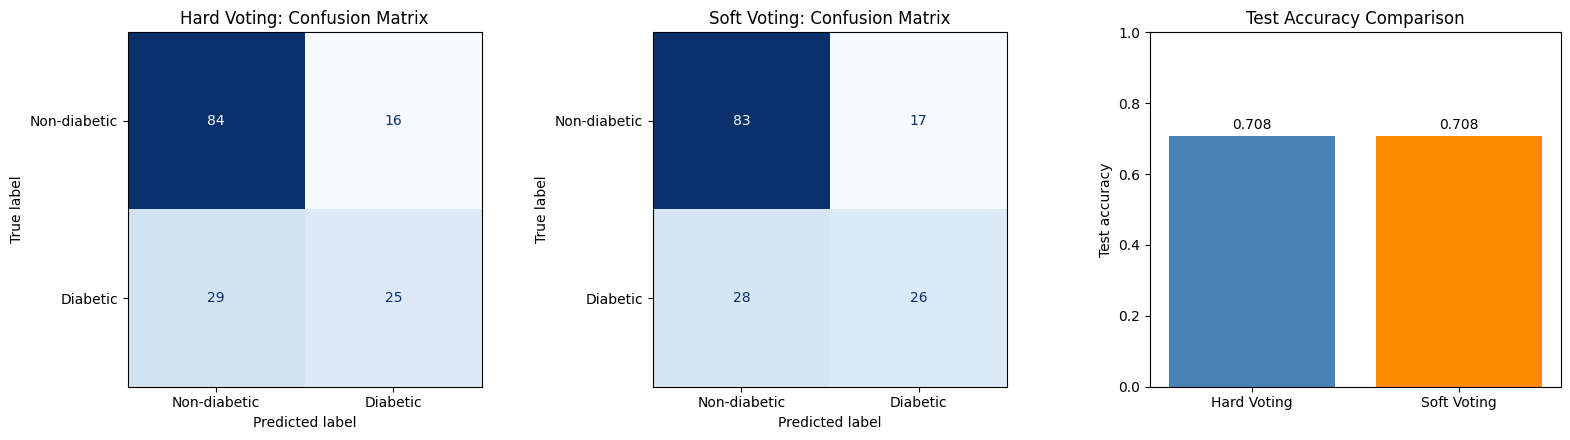

In [5]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

estimators = [
    ("lr", LogisticRegression(max_iter=1000)),
    ("svc", SVC(probability=True, random_state=42)),
    ("dt", DecisionTreeClassifier(random_state=42)),
]

models = {
    "Hard Voting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("voting", VotingClassifier(estimators, voting="hard")),
    ]),
    "Soft Voting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("voting", VotingClassifier(estimators, voting="soft")),
    ]),
}

accuracies = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    accuracies[name] = accuracy_score(y_test, predictions[name])

    print(f"{name}: test accuracy = {accuracies[name]:.3f}")
    print(classification_report(y_test, predictions[name],
                                target_names=["Non-diabetic", "Diabetic"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes[:2], models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name],
        display_labels=["Non-diabetic", "Diabetic"],
        cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name}: Confusion Matrix")

axes[2].bar(accuracies.keys(), accuracies.values(), color=["steelblue", "darkorange"])
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("Test accuracy")
axes[2].set_title("Test Accuracy Comparison")
for i, acc in enumerate(accuracies.values()):
    axes[2].text(i, acc + 0.02, f"{acc:.3f}", ha="center")

plt.tight_layout()
plt.show()

#### Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.

This cell trains a Bagging Classifier and compares its out-of-bag (OOB) score with its test accuracy.

1. **Build the Bagging Classifier.** It uses decision trees as the base estimators (`DecisionTreeClassifier`). With `bootstrap=True`, each tree is trained on a random sample of the training data drawn with replacement, so some rows are repeated and others are left out. `oob_score=True` tells the model to evaluate itself on those left-out rows.

2. **Train the model.** The classifier is fitted on the training set from Task 5.

3. **Get both scores.**
   - The **OOB score** is the accuracy on the training rows each tree did not see. Every row is predicted only by the trees that left it out, so it works as a built-in validation score that needs no separate data.
   - The **test accuracy** is the accuracy on the held-out test set.

4. **Plot the results.** A single bar chart shows the OOB score and the test accuracy side by side so they can be compared.

OOB score:     0.748
Test accuracy: 0.727


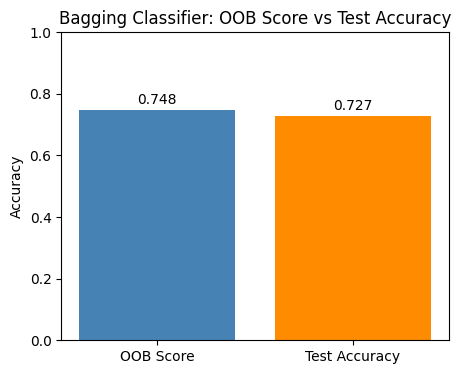

In [6]:
import matplotlib.pyplot as plt
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42,
)
bagging.fit(X_train, y_train)

oob_score = bagging.oob_score_
test_accuracy = bagging.score(X_test, y_test)

print(f"OOB score:     {oob_score:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

plt.figure(figsize=(5, 4))
bars = plt.bar(["OOB Score", "Test Accuracy"], [oob_score, test_accuracy],
               color=["steelblue", "darkorange"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Bagging Classifier: OOB Score vs Test Accuracy")
for bar, value in zip(bars, [oob_score, test_accuracy]):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.3f}", ha="center")
plt.show()

#### Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

This cell trains a Random Forest Classifier, evaluates it on the test set, and plots which features it relies on most.

1. **Build the Random Forest.** It is an ensemble of 100 decision trees. With `max_features="sqrt"`, each split considers only a random subset of the features (the square root of the total, so 2 of the 8) instead of all of them. This feature subsetting makes the trees less similar to each other, which makes the combined model more robust.

2. **Train the model.** The forest is fitted on the training set from Task 5.

3. **Evaluate on the test set.** The code prints the test accuracy, which is the share of test patients the model classifies correctly.

4. **Plot the feature importances.** `feature_importances_` gives the Mean Decrease in Impurity (MDI) for each feature: how much, on average, the splits on that feature reduce impurity across all trees, with the values summing to 1. A horizontal bar chart shows the features sorted from most to least important.

Test accuracy: 0.779


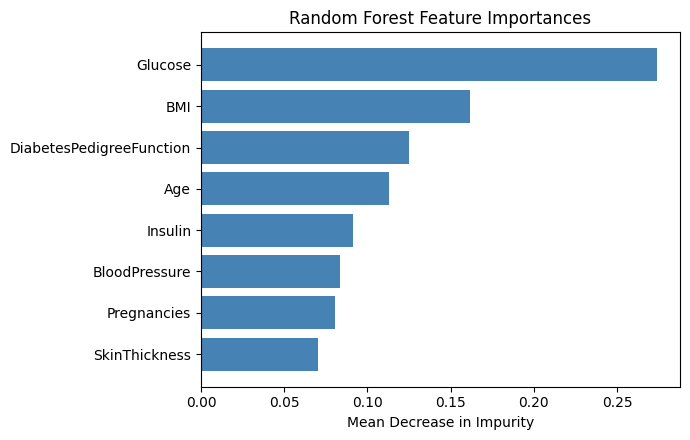

In [7]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
)
rf.fit(X_train, y_train)

test_accuracy = rf.score(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.3f}")

importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importances.index, importances.values, color="steelblue")
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

#### Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

This cell trains an AdaBoost Classifier and compares its training and test performance as boosting progresses.

1. **Convert the data to arrays.** The training and test features are converted to plain NumPy arrays with `to_numpy()`, so scikit-learn does not warn about missing feature names when the staged predictions are made.

2. **Build the AdaBoost Classifier.** The base estimator is a decision stump, a decision tree limited to one split (`max_depth=1`). AdaBoost trains 200 stumps one after another. After each stump, the weights of the training samples it misclassified are increased, so the next stump focuses on the hardest samples. Each stump also gets a vote weight based on its accuracy, and the final prediction combines all the weighted votes.

3. **Train the model.** The classifier is fitted on the training set from Task 5.

4. **Evaluate training versus test performance.** The code prints the final training and test accuracy. It also uses `staged_predict()` to get the predictions after each added stump, and `accuracy_score` to turn them into accuracies. This shows how both accuracies change as boosting progresses.

5. **Plot the results.** A line chart shows training accuracy and test accuracy against the number of stumps. A growing gap between the two lines indicates overfitting.

Training accuracy: 0.822
Test accuracy:     0.760


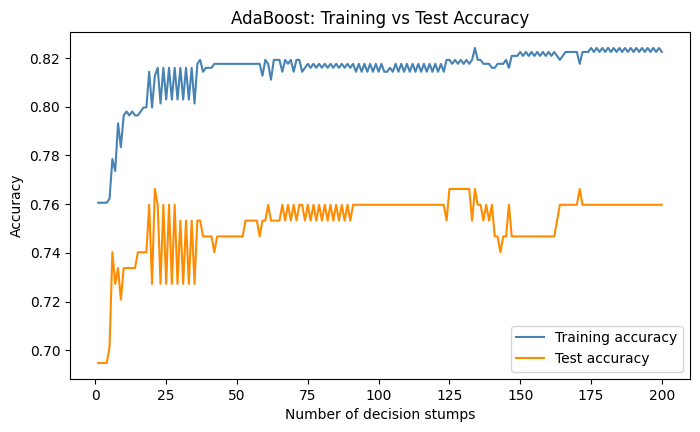

In [8]:
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X_train_arr = X_train.to_numpy()
X_test_arr = X_test.to_numpy()

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200,
    random_state=42,
)
ada.fit(X_train_arr, y_train)

print(f"Training accuracy: {ada.score(X_train_arr, y_train):.3f}")
print(f"Test accuracy:     {ada.score(X_test_arr, y_test):.3f}")

train_scores = [accuracy_score(y_train, pred) for pred in ada.staged_predict(X_train_arr)]
test_scores = [accuracy_score(y_test, pred) for pred in ada.staged_predict(X_test_arr)]
n_stumps = range(1, len(train_scores) + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(n_stumps, train_scores, label="Training accuracy", color="steelblue")
plt.plot(n_stumps, test_scores, label="Test accuracy", color="darkorange")
plt.xlabel("Number of decision stumps")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Training vs Test Accuracy")
plt.legend()
plt.show()